In [45]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.preprocessing import LabelEncoder
from sklearn.svm import SVC
from sklearn.multiclass import OneVsRestClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

from sentence_transformers import SentenceTransformer
from sklearn.metrics.pairwise import cosine_similarity


In [46]:
train_df=pd.read_csv('clean_train_final.csv')
test_df=pd.read_csv('clean_test_final.csv')

In [47]:
print("Original training data size:", len(train_df))
print("Original testing data size:", len(test_df))

Original training data size: 1248
Original testing data size: 313


In [48]:
train_df.columns

Index(['ID', 'Query', 'Priority', 'Category'], dtype='object')

In [49]:
train_df["Query"]=train_df["Query"].fillna("")
test_df["Query"]=test_df["Query"].fillna("")

In [50]:
train_df=train_df.dropna(
    subset=["Query","Priority","Category"]
)
test_df=test_df.dropna(
    subset=["Query","Priority","Category"]
)

In [51]:
before=len(train_df)
train_df=train_df.drop_duplicates(subset=["Query"])
after=len(train_df)
print("Number of duplicate entries:", before-after)

test_df=test_df.drop_duplicates(subset=["Query"])

Number of duplicate entries: 0


In [52]:
X_train=train_df["Query"].astype(str)
X_test=test_df["Query"].astype(str)

y_category_train=train_df["Category"]
y_category_test=test_df["Category"]

y_priority_train=train_df["Priority"]
y_priority_test=test_df["Priority"]


In [53]:
tfidf= TfidfVectorizer(
    lowercase=True,
    stop_words="english",
    ngram_range=(1,2)
)


In [54]:
X_train_tfidf=tfidf.fit_transform(X_train)
X_test_tfidf=tfidf.transform(X_test)

print("\nTF-IDF training shape:",X_train_tfidf.shape)
print("TF-IDF testing shape:",X_test_tfidf.shape)


TF-IDF training shape: (1248, 765)
TF-IDF testing shape: (313, 765)


In [55]:
category_encoder=LabelEncoder()
y_category_train_encoded=category_encoder.fit_transform(y_category_train)
y_category_test_encoded=category_encoder.transform(y_category_test)
print ("\nCategory classes:")
print(category_encoder.classes_)


Category classes:
['Academic & Courses' 'Administration & Documents'
 'Campus Facilities & Maintenance' 'Exams & Assessment'
 'Hostel & Accommodation' 'IT & Digital Services'
 'Internships & Placements' 'Library' 'Student Activities & Events'
 'Transport & Parking']


In [56]:
priority_encoder = LabelEncoder()
y_priority_train_encoded = priority_encoder.fit_transform(y_priority_train)
y_priority_test_encoded = priority_encoder.transform(y_priority_test)
print("\nPriority classes:")
print(priority_encoder.classes_)


Priority classes:
['High' 'Low' 'Medium']


In [57]:
category_svm=OneVsRestClassifier(
    SVC(
        C=0.1,
        kernel="linear"
    )
)

In [58]:
category_svm.fit(X_train_tfidf,y_category_train_encoded)

OneVsRestClassifier(estimator=SVC(C=0.1, kernel='linear'))

In [59]:
print("\nNumber of Category SVMs:",len(category_svm.estimators_))


Number of Category SVMs: 10


In [60]:
priority_svm=OneVsRestClassifier(
    SVC(
        C=0.1,
        kernel="linear"
    )
)

In [61]:
priority_svm.fit(
    X_train_tfidf,
    y_priority_train_encoded
)

OneVsRestClassifier(estimator=SVC(C=0.1, kernel='linear'))

In [62]:
print("Number of Priority SVMs:",len(priority_svm.estimators_))

Number of Priority SVMs: 3


In [63]:
category_predictions = category_svm.predict(
    X_test_tfidf
)

category_accuracy = accuracy_score(
    y_category_test_encoded,
    category_predictions
)

print("\n==============================")
print("CATEGORY MODEL RESULTS")
print("==============================")

print("Category Accuracy:",
      category_accuracy)

print(
    classification_report(
        y_category_test_encoded,
        category_predictions,
        target_names=category_encoder.classes_
    )
)



CATEGORY MODEL RESULTS
Category Accuracy: 1.0
                                 precision    recall  f1-score   support

             Academic & Courses       1.00      1.00      1.00        51
     Administration & Documents       1.00      1.00      1.00        56
Campus Facilities & Maintenance       1.00      1.00      1.00         9
             Exams & Assessment       1.00      1.00      1.00        68
         Hostel & Accommodation       1.00      1.00      1.00         4
          IT & Digital Services       1.00      1.00      1.00        43
       Internships & Placements       1.00      1.00      1.00        12
                        Library       1.00      1.00      1.00        20
    Student Activities & Events       1.00      1.00      1.00        41
            Transport & Parking       1.00      1.00      1.00         9

                       accuracy                           1.00       313
                      macro avg       1.00      1.00      1.00       313
  

In [64]:
priority_predictions = priority_svm.predict(
    X_test_tfidf
)

priority_accuracy = accuracy_score(
    y_priority_test_encoded,
    priority_predictions
)

print("\n==============================")
print("PRIORITY MODEL RESULTS")
print("==============================")

print("Priority Accuracy:",
      priority_accuracy)

print(
    classification_report(
        y_priority_test_encoded,
        priority_predictions,
        target_names=priority_encoder.classes_
    )
)



PRIORITY MODEL RESULTS
Priority Accuracy: 0.9361022364217252
              precision    recall  f1-score   support

        High       0.98      0.90      0.94       103
         Low       0.93      0.95      0.94       111
      Medium       0.90      0.96      0.93        99

    accuracy                           0.94       313
   macro avg       0.94      0.94      0.94       313
weighted avg       0.94      0.94      0.94       313



In [65]:
cm_category = confusion_matrix(
    y_category_test_encoded,
    category_predictions
)

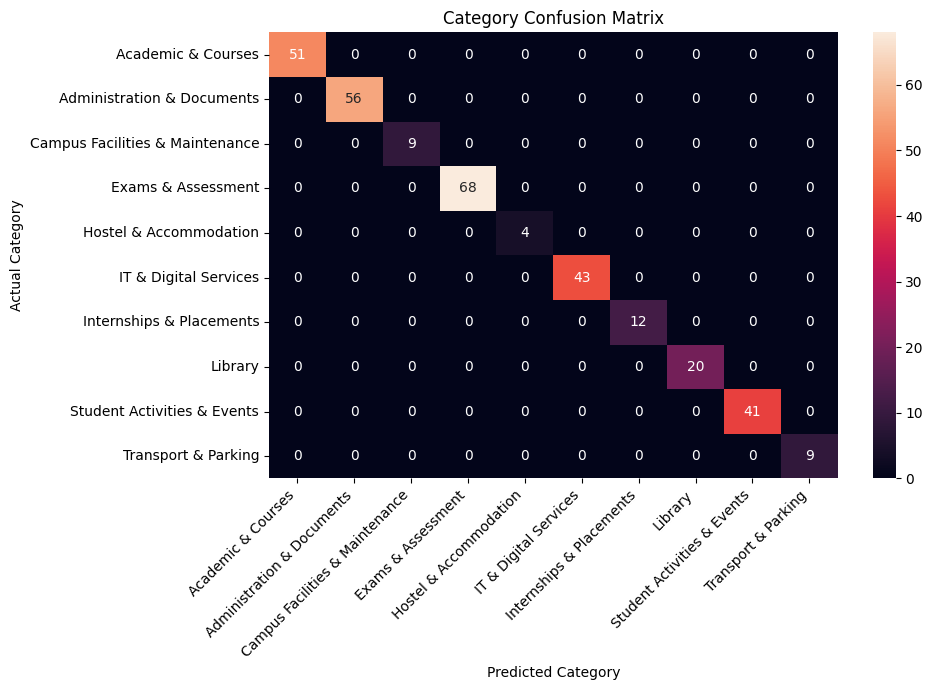

In [66]:
plt.figure(figsize=(10, 7))

sns.heatmap(
    cm_category,
    annot=True,
    fmt="d",
    xticklabels=category_encoder.classes_,
    yticklabels=category_encoder.classes_
)

plt.xlabel("Predicted Category")
plt.ylabel("Actual Category")
plt.title("Category Confusion Matrix")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()


In [67]:
cm_priority = confusion_matrix(
    y_priority_test_encoded,
    priority_predictions
)

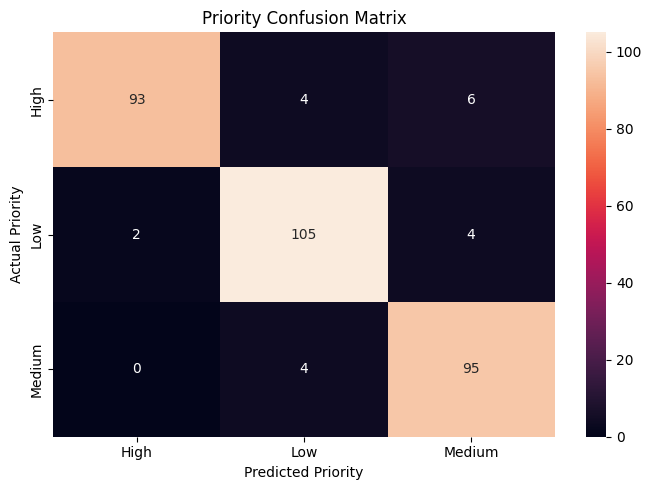

In [68]:
plt.figure(figsize=(7, 5))

sns.heatmap(
    cm_priority,
    annot=True,
    fmt="d",
    xticklabels=priority_encoder.classes_,
    yticklabels=priority_encoder.classes_
)

plt.xlabel("Predicted Priority")
plt.ylabel("Actual Priority")
plt.title("Priority Confusion Matrix")
plt.tight_layout()
plt.show()


In [69]:
sbert_model = SentenceTransformer(
    "all-MiniLM-L6-v2"
)

Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

In [70]:
existing_complaints = train_df["Query"].tolist()

In [71]:
existing_embeddings = sbert_model.encode(
    existing_complaints,
    convert_to_numpy=True,
    normalize_embeddings=True
)

print("\nSBERT embedding shape:")
print(existing_embeddings.shape)


SBERT embedding shape:
(1248, 384)


In [74]:
import numpy as np
def check_duplicate(complaint, threshold=0.80):

    new_embedding = sbert_model.encode(
        [complaint],
        convert_to_numpy=True,
        normalize_embeddings=True
    )

    similarity_scores = cosine_similarity(
        new_embedding,
        existing_embeddings
    )[0]

    best_match_index = np.argmax(similarity_scores)

    best_score = similarity_scores[best_match_index]

    best_match = existing_complaints[best_match_index]

    if best_score >= threshold:
        return True, best_match, best_score
    else:
        return False, best_match, best_score


#test

complaint = "WiFi is not working in computer lab"

is_duplicate, best_match, score = check_duplicate(complaint)

print("Best Match:", best_match)
print("Similarity Score:", score)
print("Duplicate:", is_duplicate)

Best Match: Hi, Campus WiFi password reset process kindly help.
Similarity Score: 0.54851437
Duplicate: False


In [75]:
def process_new_complaint(
    complaint,
    duplicate_threshold=0.80
):

    print("\n================================")
    print("NEW COMPLAINT")
    print("================================")

    print("Complaint:", complaint)

In [80]:
def check_duplicate(complaint, duplicate_threshold=0.80):

    new_embedding = sbert_model.encode(
        [complaint],
        convert_to_numpy=True,
        normalize_embeddings=True
    )

    similarity_scores = cosine_similarity(
        new_embedding,
        existing_embeddings
    )[0]

    best_match_index = similarity_scores.argmax()
    best_score = similarity_scores[best_match_index]
    best_match = existing_complaints[best_match_index]

    if best_score >= duplicate_threshold:
        return True, best_match, best_score
    else:
        return False, best_match, best_score

In [82]:
if is_duplicate:
    print("\n⚠ Duplicate complaint detected!")
    print("Similar existing complaint:")
    print(similar_complaint)
else:
    print("\n✅ New complaint, no duplicate found.")


✅ New complaint, no duplicate found.


In [83]:
complaint_tfidf = tfidf.transform(
        [complaint]
    )

In [85]:
category_prediction_encoded = category_svm.predict(complaint_tfidf)[0]

predicted_category = category_encoder.inverse_transform(
    [category_prediction_encoded]
)[0]

print("Predicted Category:", predicted_category)

Predicted Category: IT & Digital Services


In [87]:
priority_prediction_encoded = priority_svm.predict(complaint_tfidf)[0]

predicted_priority = priority_encoder.inverse_transform(
    [priority_prediction_encoded]
)[0]

print("Predicted Priority:", predicted_priority)

Predicted Priority: High


In [90]:
    print("\nNo duplicate found.")

    print(
        "Predicted Category:",
        predicted_category
    )

    print(
        "Predicted Priority:",
        predicted_priority
    )


No duplicate found.
Predicted Category: IT & Digital Services
Predicted Priority: High


In [91]:
new_complaint = (
    "Internet connection is not working "
    "in the computer laboratory"
)

process_new_complaint(
    new_complaint,
    duplicate_threshold=0.80
)


NEW COMPLAINT
Complaint: Internet connection is not working in the computer laboratory
